# Confrontation des deux datasets et stratégie de consolidation

Les quatre notebooks précédents ont analysé chaque jeu séparément. Il s'agit maintenant
de décider **comment les combiner**, en répondant à deux questions distinctes :

1. Les deux jeux sont-ils comparables — mêmes variables, mêmes échelles, mêmes cultures ?
2. Lequel permet de **départager les cultures**, ce dont `/recommend` a besoin ?

Rappel des deux constats qui rendent cette étape décisive :

- Jeu simulé : la culture n'a **aucun** effet sur le rendement, même à conditions
  comparables (0,028 t/ha d'écart maximum, notebook 01).
- Jeu reconstruit : les cultures diffèrent d'un **facteur 12,8** (notebook 04).

## Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))

from src import config, utils
from src.data import crop_yield_prediction as cyp
from src.data import preparation
from src.data.crop_mapping import CROP_TO_FAO_ITEM, IMPUTATION_RULES

utils.style()
np.random.seed(config.SEED)

## Lecture des deux datasets

In [2]:
agri = preparation.typage(preparation.charge())
histo = pd.read_csv(config.CROP_YIELD_PREDICTION_CSV)

print(f"Agriculture CropYield : {agri.shape[0]:,} lignes x {agri.shape[1]} colonnes")
print(f"CropYield Prediction  : {histo.shape[0]:,} lignes x {histo.shape[1]} colonnes")

Agriculture CropYield : 1,000,000 lignes x 10 colonnes
CropYield Prediction  : 25,527 lignes x 8 colonnes


## Vue d'ensemble

In [3]:
pd.DataFrame({
    "Agriculture CropYield": {
        "unité observée": "une parcelle",
        "lignes": f"{len(agri):,}",
        "cultures": agri["Crop"].nunique(),
        "dimension temporelle": "aucune",
        "dimension géographique": "zone abstraite (N/S/E/O)",
        "pratiques agricoles": "engrais, irrigation",
        "sol": "6 textures",
        "origine": "simulée",
    },
    "CropYield Prediction": {
        "unité observée": "pays × année × culture",
        "lignes": f"{len(histo):,}",
        "cultures": histo["crop"].nunique(),
        "dimension temporelle": "1990-2013",
        "dimension géographique": f"{histo['iso3'].nunique()} pays",
        "pratiques agricoles": "aucune (pesticides = total national)",
        "sol": "absent",
        "origine": "FAO / Banque mondiale",
    },
})

,Agriculture CropYield,CropYield Prediction
unité observée,une parcelle,pays × année × culture
lignes,"1,000,000","25,527"
cultures,6,10
dimension temporelle,aucune,1990-2013
dimension géographique,zone abstraite (N/S/E/O),203 pays
pratiques agricoles,"engrais, irrigation",aucune (pesticides = total national)
sol,6 textures,absent
origine,simulée,FAO / Banque mondiale


**Observations :**

- Les **unités d'observation sont incompatibles** : une parcelle contre un pays sur une
  année. Empiler les lignes mélangerait deux populations distinctes.
- Chaque jeu porte ce qui manque à l'autre : les pratiques et le sol d'un côté, l'effet
  culture et la profondeur temporelle de l'autre.
- **La culture est la seule dimension commune** — donc la seule clé de jointure possible.

## Variables comparables

In [4]:
pd.DataFrame([
    {"grandeur": "rendement", "Agriculture CropYield": "Yield_tons_per_hectare (t/ha)",
     "CropYield Prediction": "yield_t_ha (t/ha)", "comparable": "oui, après conversion"},
    {"grandeur": "température", "Agriculture CropYield": "Temperature_Celsius (°C, saison culturale)",
     "CropYield Prediction": "avg_temp (°C, moyenne annuelle)", "comparable": "NON — fenêtre différente"},
    {"grandeur": "pluie", "Agriculture CropYield": "Rainfall_mm (saison culturale)",
     "CropYield Prediction": "rain_mm (normale annuelle)", "comparable": "NON — fenêtre différente"},
    {"grandeur": "culture", "Agriculture CropYield": "Crop (6)",
     "CropYield Prediction": "crop (10)", "comparable": "oui, après harmonisation"},
]).set_index("grandeur")

,Agriculture CropYield,CropYield Prediction,comparable
grandeur,,,
rendement,Yield_tons_per_hectare (t/ha),yield_t_ha (t/ha),"oui, après conversion"
température,"Temperature_Celsius (°C, saison culturale)","avg_temp (°C, moyenne annuelle)",NON — fenêtre différente
pluie,Rainfall_mm (saison culturale),rain_mm (normale annuelle),NON — fenêtre différente
culture,Crop (6),crop (10),"oui, après harmonisation"


### Variables non comparables

In [5]:
comparaison = pd.DataFrame({
    "Agriculture CropYield": [
        f"{agri['Rainfall_mm'].min():.0f} – {agri['Rainfall_mm'].max():.0f}",
        f"{agri['Rainfall_mm'].median():.0f}",
        f"{agri['Temperature_Celsius'].min():.1f} – {agri['Temperature_Celsius'].max():.1f}",
        f"{agri['Temperature_Celsius'].median():.1f}",
    ],
    "CropYield Prediction": [
        f"{histo['rain_mm'].min():.0f} – {histo['rain_mm'].max():.0f}",
        f"{histo['rain_mm'].median():.0f}",
        f"{histo['avg_temp'].min():.1f} – {histo['avg_temp'].max():.1f}",
        f"{histo['avg_temp'].median():.1f}",
    ],
}, index=["pluie : plage (mm)", "pluie : médiane (mm)",
          "température : plage (°C)", "température : médiane (°C)"])
comparaison

,Agriculture CropYield,CropYield Prediction
pluie : plage (mm),100 – 1000,51 – 3240
pluie : médiane (mm),550,1150
température : plage (°C),15.0 – 40.0,-3.4 – 30.4
température : médiane (°C),27.5,21.2


In [6]:
# La température du jeu simulé est-elle une moyenne annuelle, comme celle du jeu historique ?
# Le jeu simulé a un plancher net ; on regarde combien de pays-années RÉELS passent dessous.
# La question ne porte que sur les lignes dont la température est connue : inclure les
# manquantes gonflerait le dénominateur et sous-estimerait la part.
connus = histo.dropna(subset=["avg_temp"])
PLANCHER = agri["Temperature_Celsius"].min()
INVERSE_T = {v: k for k, v in CROP_TO_FAO_ITEM.items() if v}

lignes = []
for item, culture in INVERSE_T.items():
    sous = connus.loc[connus["crop"] == item, "avg_temp"]
    lignes.append({
        "culture": culture,
        f"part sous {PLANCHER:.0f} °C": f"{(sous < PLANCHER).mean():.1%}",
        "médiane réelle (°C)": round(sous.median(), 1),
        "pays-années": len(sous),
    })

print(f"plancher du jeu simulé : {PLANCHER:.1f} °C")
print(f"pays dont la moyenne annuelle est sous ce plancher : "
      f"{connus.loc[connus.avg_temp < PLANCHER, 'iso3'].nunique()} sur {connus.iso3.nunique()}")
froids = connus[connus.avg_temp < PLANCHER].groupby("area")["avg_temp"].mean().sort_values()
print("exemples :", ", ".join(f"{p} {t:.1f} °C" for p, t in froids.head(5).items()))
pd.DataFrame(lignes).set_index("culture")

plancher du jeu simulé : 15.0 °C
pays dont la moyenne annuelle est sous ce plancher : 53 sur 137
exemples : Mongolia -1.9 °C, Norway 3.5 °C, Russian Federation 4.0 °C, Kazakhstan 5.2 °C, Finland 5.5 °C


,part sous 15 °C,médiane réelle (°C),pays-années
culture,,,
Maize,30.6%,20.2,2828
Wheat,44.2%,16.3,2432
Rice,19.7%,22.3,2161
Soybean,33.5%,18.8,1853


**Observations — aucune des deux variables climatiques n'est comparable d'un jeu à l'autre :**

- **La pluie du jeu simulé plafonne à 1 000 mm, quand la médiane du jeu historique la
  dépasse.** L'une est une pluie de saison culturale, l'autre une normale annuelle : même
  nom, grandeur différente.

- **La température non plus**, et c'est moins évident parce que l'unité est la même des deux
  côtés. Le test ci-dessus le démontre : le jeu simulé a un **plancher net à 15,0 °C**, or
  **44 % des pays-années réels cultivant du blé** sont sous ce seuil en moyenne annuelle, et
  **53 pays sur 137** le sont — dont la Russie (4,0 °C), le Kazakhstan (5,2 °C) et la
  Finlande (5,5 °C), qui comptent parmi les premiers producteurs de blé au monde.

  Si la température du simulateur était une moyenne annuelle, il exclurait donc près de la
  moitié de la production mondiale de blé. C'est impossible pour un jeu dont la grille de
  modalités est exhaustive et uniforme (notebook 01) : un catalogue conçu pour couvrir tous
  les cas ne tronquerait pas la moitié de la ceinture céréalière.

  **Lecture retenue : le simulateur décrit une saison culturale, pas une année civile** — et
  cela pour la pluie comme pour la température. Un plancher de 15 °C n'a rien d'arbitraire
  sur une température de croissance : en dessous, une céréale ne pousse quasiment pas.

> **Règle retenue pour la fusion.** Aucun descripteur climatique issu du jeu historique ne
> sera juxtaposé en valeur brute aux mesures de parcelle. La pluie est portée en
> **percentile**. La température est conservée en °C, faute de transformation évidente, mais
> **l'écart entre une température de parcelle et une niche thermique nationale n'est pas un
> écart agronomique** : il mélange deux fenêtres temporelles. C'est une limite de
> `temp_dev_from_niche`, à vérifier à l'étape 2 plutôt qu'à supposer.

## Cultures communes

In [7]:
correspondance = pd.DataFrame([
    {"culture (jeu simulé)": culture,
     "équivalent FAO": item if item else "— absent —",
     "statut": "exact" if item == culture else ("harmonisé" if item else "IMPUTÉ")}
    for culture, item in CROP_TO_FAO_ITEM.items()
])
communes = [i for i in CROP_TO_FAO_ITEM.values() if i]
print("intersection littérale des libellés :",
      sorted(set(agri['Crop'].unique()) & set(histo['crop'].unique())))
print(f"cultures appariées après harmonisation : {len(communes)} sur 6")
correspondance

intersection littérale des libellés : ['Maize', 'Wheat']
cultures appariées après harmonisation : 4 sur 6


,culture (jeu simulé),équivalent FAO,statut
0,Maize,Maize,exact
1,Wheat,Wheat,exact
2,Rice,"Rice, paddy",harmonisé
3,Soybean,Soybeans,harmonisé
4,Barley,— absent —,IMPUTÉ
5,Cotton,— absent —,IMPUTÉ


**Observations :**

- Seuls **Maize** et **Wheat** correspondent littéralement. Deux de plus s'apparient après
  harmonisation (`Rice` → `Rice, paddy`, `Soybean` → `Soybeans`).
- **L'orge et le coton sont totalement absents** du jeu historique. Les exclure
  reviendrait à jeter un tiers du jeu simulé et à ne plus recommander que quatre
  cultures ; chacune reçoit donc le profil d'une culture donneuse documentée, signalée
  comme imputée.
- **Cette imputation vaut pour l'enrichissement du dataset, pas pour un classement.**
  Dans un classement, l'orge recopierait le rang du blé et le coton celui du sorgho.
  L'étape 2 les retire donc du classement de `/recommend` (notebook 10). Elles restent
  servies par `/predict`.

In [8]:
for culture, regle in IMPUTATION_RULES.items():
    rendement = (f"{regle.yield_override_t_ha} t/ha" if regle.yield_override_t_ha
                 else "celui de la donneuse")
    print(f"{culture}\n  donneuse : {regle.donor_item}\n  rendement : {rendement}"
          f"\n  motif    : {regle.rationale}\n")

Barley
  donneuse : Wheat
  rendement : celui de la donneuse
  motif    : Barley is a temperate cereal with the same growing calendar, input requirements and yield magnitude as wheat. Wheat's FAO profile is transferred whole, yield included.

Cotton
  donneuse : Sorghum
  rendement : 2.2 t/ha
  motif    : Cotton is a fibre crop: no cereal can proxy its yield, so the reference yield is set to the FAO world average for seed cotton (~2.2 t/ha). Sorghum -- a warm, semi-arid crop -- only donates the climatic and pesticide-intensity profile.



## Comparaison des distributions sur les cultures communes

In [9]:
INVERSE = {v: k for k, v in CROP_TO_FAO_ITEM.items() if v}
histo_communes = histo[histo["crop"].isin(INVERSE)].assign(
    culture=lambda d: d["crop"].map(INVERSE)
)
agri_communes = agri[agri["Crop"].isin(INVERSE.values())]
print(f"jeu historique, cultures communes : {len(histo_communes):,} lignes")
print(f"jeu simulé,     cultures communes : {len(agri_communes):,} lignes")

jeu historique, cultures communes : 11,648 lignes
jeu simulé,     cultures communes : 666,638 lignes


### Rendement par culture

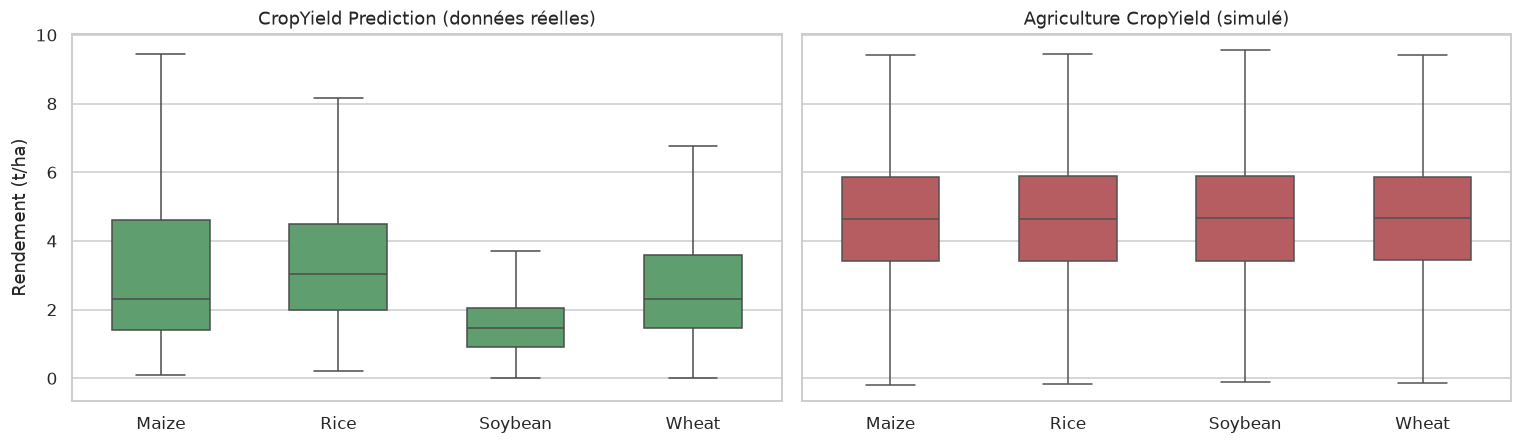

         historique (médiane)  simulé (médiane)  écart
Maize                    2.30              4.64   2.34
Rice                     3.03              4.65   1.62
Soybean                  1.46              4.66   3.19
Wheat                    2.31              4.66   2.35

étendue des médianes — historique : 2.07x | simulé : 1.00x


In [10]:
ordre = sorted(INVERSE.values())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)

sns.boxplot(data=histo_communes, x="culture", y="yield_t_ha", order=ordre,
            ax=axes[0], showfliers=False, width=0.55, color="#55A868")
axes[0].set_title("CropYield Prediction (données réelles)")
axes[0].set_ylabel("Rendement (t/ha)")
axes[0].set_xlabel("")

sns.boxplot(data=agri_communes.sample(100_000, random_state=config.SEED),
            x="Crop", y="Yield_tons_per_hectare", order=ordre,
            ax=axes[1], showfliers=False, width=0.55, color="#C44E52")
axes[1].set_title("Agriculture CropYield (simulé)")
axes[1].set_xlabel("")
utils.enregistre("05_rendement_par_culture_compare")
plt.show()

resume = pd.DataFrame({
    "historique (médiane)": histo_communes.groupby("culture")["yield_t_ha"].median(),
    "simulé (médiane)": agri_communes.groupby("Crop", observed=True)["Yield_tons_per_hectare"].median(),
})
resume["écart"] = resume["simulé (médiane)"] - resume["historique (médiane)"]
print(resume.round(2).to_string())
print(f"\nétendue des médianes — historique : "
      f"{resume['historique (médiane)'].max() / resume['historique (médiane)'].min():.2f}x"
      f" | simulé : {resume['simulé (médiane)'].max() / resume['simulé (médiane)'].min():.2f}x")

**Observations :**

- **Le contraste est net** : les médianes du jeu historique s'étalent d'un facteur 2 sur
  ces quatre cultures (et 12,8 sur les dix), contre **1,00** pour le jeu simulé.
- Les rendements simulés (≈ 4,65 t/ha) sont **au-dessus de toutes les médianes
  historiques** de ces cultures. Plausibles pour une parcelle bien conduite, mais pas
  typiques d'une moyenne nationale.
- Les distributions ne se superposent pas : le simulé est symétrique et resserré,
  l'historique asymétrique et bien plus étalé.

## Capacité à différencier les cultures

Deux questions distinctes : les cultures ont-elles des rendements différents, et peut-on
**choisir une culture pour des conditions données** ? C'est la seconde qui intéresse
`/recommend`. Le rendement moyen par bande de température permet de la traiter, sur la
plage commune aux deux jeux (15-30 °C).

In [11]:
BANDES = [15, 20, 25, 30]


def rendement_par_bande(df, colonne_temp, colonne_culture, colonne_rendement):
    """Mean yield per temperature band and per crop, with the gap between crops."""
    bandes = pd.cut(df[colonne_temp], BANDES)
    table = df.pivot_table(index=bandes, columns=colonne_culture,
                           values=colonne_rendement, observed=True)
    table["écart max"] = table.max(axis=1) - table.min(axis=1)
    return table.round(2)


print("CropYield Prediction")
print(rendement_par_bande(histo_communes, "avg_temp", "culture", "yield_t_ha"), "\n")
print("Agriculture CropYield")
print(rendement_par_bande(agri_communes, "Temperature_Celsius", "Crop",
                          "Yield_tons_per_hectare"))

CropYield Prediction
culture   Maize  Rice  Soybean  Wheat  écart max
avg_temp                                        
(15, 20]   3.73  4.98     1.69   2.08       3.29
(20, 25]   2.30  2.93     1.45   2.36       1.48
(25, 30]   2.84  2.94     1.26   2.07       1.68 

Agriculture CropYield
Crop                 Maize  Rice  Soybean  Wheat  écart max
Temperature_Celsius                                        
(15, 20]              4.44  4.45     4.45   4.46       0.01
(20, 25]              4.53  4.55     4.56   4.56       0.03
(25, 30]              4.65  4.66     4.64   4.66       0.02


**Observations :**

**Agriculture CropYield** — à température comparable, l'écart entre les quatre cultures
reste de l'ordre de **0,01 à 0,03 t/ha**, soit moins de 1 %. L'EDA (0,028 t/ha) et l'ACP
(aucune séparation des cultures sur les plans factoriels) donnaient déjà ce résultat. Ce
jeu permet d'estimer un rendement à partir de conditions de parcelle, **mais pas de
départager les cultures**.

**CropYield Prediction** — à température comparable, l'écart entre cultures atteint
plusieurs t/ha, et **l'ordre entre cultures change d'une bande à l'autre**. Ce n'est donc
pas un simple effet de niveau global : la température interagit réellement avec le choix
de la culture. Un classement est envisageable.

**Mais une réserve importante :** les variables disponibles décrivent le climat **moyen
d'un pays**. Ce qui différencie les cultures tient donc pour une large part à *l'endroit
où elles sont cultivées*, et non à leurs qualités agronomiques intrinsèques. Le classement
restera un ordre de grandeur à l'échelle d'un contexte climatique, pas d'une parcelle.

## Les variables clés du jeu simulé se retrouvent-elles dans les données réelles ?

Le sujet confie au second jeu un rôle précis : **valider l'analyse du premier**. Les notebooks
01 et 02 ont établi, sur le jeu simulé, la hiérarchie pluie > engrais > irrigation >
température. Reste à savoir si ce sont des propriétés de l'agriculture ou du générateur.

Seules la pluie et la température existent des deux côtés ; l'engrais et l'irrigation n'ont pas
d'équivalent FAO, d'où les proxies de la section suivante. Le jeu FAO se lit de deux façons,
qui ne disent pas la même chose :

- **entre pays** : un point par couple pays × culture, moyenné sur les années. C'est la
  comparaison la plus proche du jeu simulé, mais elle mêle le climat au niveau de
  développement de chaque pays ;
- **dans le temps** : les variations d'une année sur l'autre au sein d'un même couple
  pays × culture. L'effet pays disparaît, et l'essentiel de la tendance technologique avec.

La même mesure est utilisée partout : la corrélation de rang de Spearman avec le rendement.

In [12]:
# Same measure on both sides: Spearman correlation with yield.
simule = agri[["Yield_tons_per_hectare", "Rainfall_mm", "Temperature_Celsius",
               "Fertilizer_Used", "Irrigation_Used"]].astype(float)
rho_simule = simule.corr(method="spearman")["Yield_tons_per_hectare"]

reel = histo.assign(log_pesticides=np.log1p(histo["pesticides_t"]))
VARIABLES_REELLES = ["rain_mm", "avg_temp", "log_pesticides"]

# Between countries: one point per country x crop, averaged over the years.
par_pays = reel.groupby(["crop", "iso3"])[["yield_t_ha", *VARIABLES_REELLES]].mean()
entre_pays = pd.DataFrame({
    culture: {v: bloc["yield_t_ha"].corr(bloc[v], method="spearman") for v in VARIABLES_REELLES}
    for culture, bloc in par_pays.groupby(level="crop")
}).T

# Over time: year-to-year changes within a country x crop pair.
reel = reel.sort_values(["iso3", "crop", "year"])
variations = reel.groupby(["iso3", "crop"])[["yield_t_ha", *VARIABLES_REELLES]].diff()
variations["crop"] = reel["crop"]
dans_le_temps = pd.DataFrame({
    culture: {v: bloc["yield_t_ha"].corr(bloc[v], method="spearman")
              for v in ["avg_temp", "log_pesticides"]}
    for culture, bloc in variations.groupby("crop")
}).T
print(f"plus forte variation annuelle de la pluie au sein d'un pays : "
      f"{variations['rain_mm'].abs().max():.1f} mm -> non mesurable dans le temps")

synthese = pd.DataFrame({
    "simulé": [rho_simule["Rainfall_mm"], rho_simule["Temperature_Celsius"],
               rho_simule["Fertilizer_Used"], rho_simule["Irrigation_Used"]],
    "FAO entre pays (médiane)": [entre_pays["rain_mm"].median(), entre_pays["avg_temp"].median(),
                                 entre_pays["log_pesticides"].median(), np.nan],
    "FAO entre pays (min)": [entre_pays["rain_mm"].min(), entre_pays["avg_temp"].min(),
                             entre_pays["log_pesticides"].min(), np.nan],
    "FAO entre pays (max)": [entre_pays["rain_mm"].max(), entre_pays["avg_temp"].max(),
                             entre_pays["log_pesticides"].max(), np.nan],
    "FAO dans le temps (médiane)": [np.nan, dans_le_temps["avg_temp"].median(),
                                    dans_le_temps["log_pesticides"].median(), np.nan],
}, index=["pluie", "température", "intrants (engrais ; proxy FAO : pesticides)",
          "irrigation (absente du jeu FAO)"])
print()
print(synthese.round(3).to_string())
print(f"\ncultures où la température est liée négativement au rendement entre pays : "
      f"{(entre_pays['avg_temp'] < 0).sum()} sur {len(entre_pays)}")
print(f"cultures où les pesticides sont liés positivement au rendement entre pays : "
      f"{(entre_pays['log_pesticides'] > 0).sum()} sur {len(entre_pays)}")

plus forte variation annuelle de la pluie au sein d'un pays : 0.0 mm -> non mesurable dans le temps

                                             simulé  FAO entre pays (médiane)  FAO entre pays (min)  FAO entre pays (max)  FAO dans le temps (médiane)
pluie                                         0.770                    -0.062                -0.265                 0.144                          NaN
température                                   0.081                    -0.322                -0.550                 0.164                       -0.019
intrants (engrais ; proxy FAO : pesticides)   0.430                     0.464                 0.214                 0.653                        0.019
irrigation (absente du jeu FAO)               0.340                       NaN                   NaN                   NaN                          NaN

cultures où la température est liée négativement au rendement entre pays : 9 sur 10
cultures où les pesticides sont liés positivement au rendem

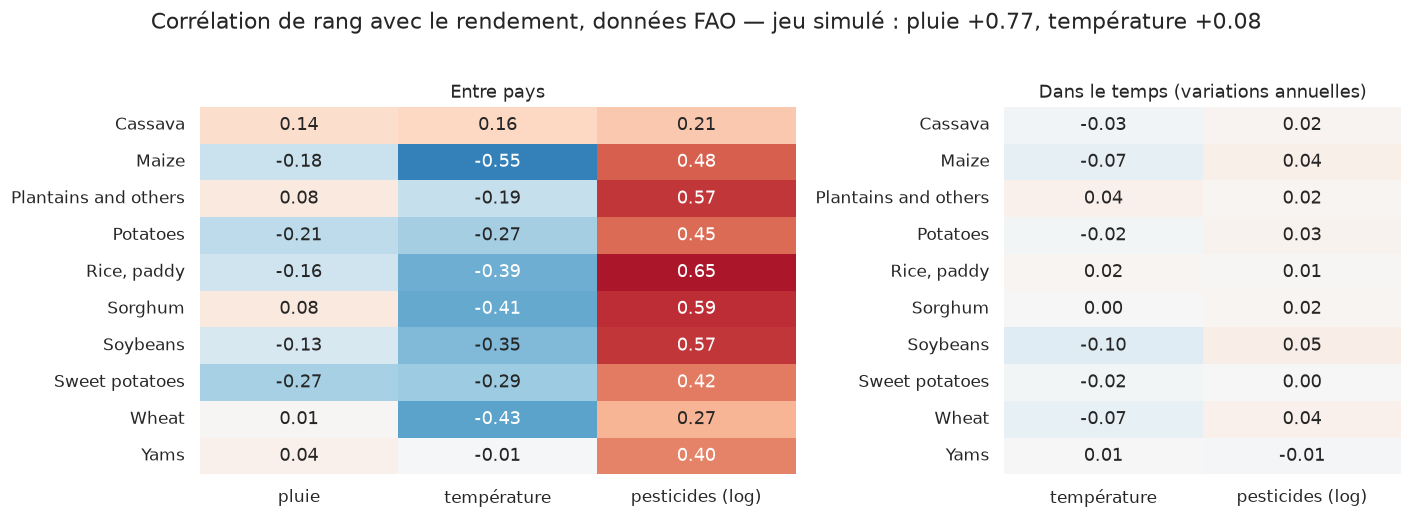

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [3, 2]})
libelles = {"rain_mm": "pluie", "avg_temp": "température", "log_pesticides": "pesticides (log)"}
for ax, (table, titre) in zip(axes, [(entre_pays, "Entre pays"),
                                     (dans_le_temps, "Dans le temps (variations annuelles)")]):
    sns.heatmap(table.rename(columns=libelles), annot=True, fmt=".2f", cmap="RdBu_r",
                vmin=-0.8, vmax=0.8, cbar=False, ax=ax)
    ax.set_title(titre)
    ax.set_ylabel("")
fig.suptitle(f"Corrélation de rang avec le rendement, données FAO — "
             f"jeu simulé : pluie {rho_simule['Rainfall_mm']:+.2f}, "
             f"température {rho_simule['Temperature_Celsius']:+.2f}", y=1.02)
utils.enregistre("05_validation_variables_cles")
plt.show()

**Observations — la validation est partielle, et c'est un résultat :**

- **La pluie n'est pas validée.** Facteur dominant du jeu simulé (ρ ≈ 0,77), elle n'est
  pratiquement pas liée au rendement entre pays FAO (médiane ≈ −0,06, de signes variés selon
  la culture). Dans le temps, elle ne se mesure même pas : la pluie FAO est une normale
  constante par pays. La section suivante en donne la raison principale : l'irrigation.
- **La température change de signe.** Légèrement positive dans le simulé, elle est négative
  entre pays pour presque toutes les cultures (médiane ≈ −0,32) : les pays chauds ont des
  rendements plus faibles. Mais ce sont aussi, en moyenne, des pays moins équipés, et d'une
  année sur l'autre le lien disparaît (≈ 0). On ne peut en tirer ni la confirmation ni la
  réfutation d'un effet agronomique.
- **Seule l'intensité en intrants va dans le même sens.** Les pesticides, proxy des intrants,
  sont liés positivement au rendement entre pays **pour les dix cultures** (médiane ≈ +0,46),
  comme l'engrais dans le simulé (+0,43). Mais ce lien est **transversal** : il disparaît dans
  le temps (≈ +0,02). Il décrit des agricultures intensives, pas l'effet d'un levier qu'on
  actionnerait.

**Conséquence pour le rapport métier.** Les chiffres « +1,50 t/ha pour l'engrais, +1,20 t/ha
pour l'irrigation, la pluie explique 58 % » décrivent **le jeu simulé**. Les données réelles en
confirment la direction pour les intrants, pas l'ampleur, et ne confirment pas le rôle dominant
de la pluie. Le rapport doit les présenter comme des ordres de grandeur issus d'un jeu simulé,
pas comme des faits agronomiques mesurés.

## Des proxies pour l'irrigation et la fertilisation

Le jeu FAO ne dit rien des pratiques. Deux de ses variables peuvent-elles en tenir lieu ?

- **Fertilisation → pesticides.** Ce sont les deux intrants achetés d'une agriculture
  intensive, et le seul intrant disponible ici. Limites : c'est un **tonnage national**, qui
  croît avec la taille du pays (d'où le logarithme), et non une dose par hectare ; et ce n'est
  pas de l'engrais. La section précédente mesure ce qu'il porte : une intensité, entre pays.
- **Irrigation → déficit de pluie.** Si la pluie FAO mesurait l'eau dont disposent les
  cultures, les rendements devraient s'effondrer dans les pays les plus secs. Sinon, c'est
  qu'une autre source d'eau compense : l'irrigation.

In [14]:
BANDES_PLUIE = [0, 300, 600, 1000, 1500, 4000]
communes_fao = list(INVERSE)
reel["pluie (mm/an)"] = pd.cut(reel["rain_mm"], BANDES_PLUIE)
print("Rendement médian (t/ha) par bande de pluie annuelle, cultures communes")
print(reel[reel["crop"].isin(communes_fao)].pivot_table(
    index="crop", columns="pluie (mm/an)", values="yield_t_ha",
    aggfunc="median", observed=True).round(2).to_string())

arides = reel[(reel["rain_mm"] < 300) & reel["crop"].isin(communes_fao)]
print(f"\nPays sous 300 mm/an, rendements médiens les plus élevés :")
print(arides.groupby(["crop", "area"])["yield_t_ha"].median()
      .sort_values(ascending=False).head(8).round(2).to_string())

Rendement médian (t/ha) par bande de pluie annuelle, cultures communes
pluie (mm/an)  (0, 300]  (300, 600]  (600, 1000]  (1000, 1500]  (1500, 4000]
crop                                                                        
Maize              2.46        3.75         3.93          1.79          2.02
Rice, paddy        3.27        3.40         4.41          2.34          3.04
Soybeans           1.65        1.45         1.74          1.15          1.40
Wheat              1.90        2.23         3.09          2.35          1.76

Pays sous 300 mm/an, rendements médiens les plus élevés :
crop         area                      
Maize        United Arab Emirates          20.87
             Kuwait                        19.73
             Jordan                        16.52
             Qatar                         12.53
Rice, paddy  Egypt                          9.34
Maize        Egypt                          7.60
Rice, paddy  Syrian Arab Republic           7.42
Maize        Iran (Islami

**Observations :**

- **Les pays les plus secs ne rendent pas moins.** Sous 300 mm par an, un maïs ou un riz
  pluvial est agronomiquement impossible ; pourtant les rendements médians de cette bande
  valent ceux des pays les plus arrosés. L'Égypte, quasiment sans pluie, produit du riz
  autour de 9 t/ha, trois fois la médiane mondiale.
- C'est la signature de l'**irrigation**. Le proxy retenu est donc : **pluie annuelle sous
  300 mm ⇒ agriculture irriguée**. Il signale l'irrigation là où elle est certaine, mais ne la
  mesure pas ailleurs.
- **Conséquence pour la validation précédente** : la pluie FAO ne mesure pas l'eau reçue par
  les cultures. L'absence de lien pluie / rendement entre pays ne réfute donc pas l'effet de
  l'eau ; elle montre que les données réelles ne permettent pas de le mesurer.
- **Conséquence pour `/recommend`** : l'effet de l'irrigation est présent dans les rendements
  FAO, mais caché dans le pays. Le modèle de l'étape 2 ne le voit qu'à travers la géographie.

## Stratégies possibles

**A. Empiler les lignes des deux jeux**

Écartée. Trois variables communes seulement, dont une de définition différente (la
pluie), quatre cultures partagées sur six et dix, et des unités d'observation
incompatibles. Empiler reviendrait à mélanger deux populations distinctes.

**B. N'utiliser qu'Agriculture CropYield**

- *Avantages :* un million de lignes, aucun manquant, des variables qu'un utilisateur
  peut renseigner pour sa parcelle, et une relation forte avec le rendement (pluie 0,765).
- *Limites :* la culture n'a aucun effet, même à conditions comparables. `/predict` est
  réalisable, **`/recommend` ne l'est pas**.

**C. N'utiliser que CropYield Prediction**

- *Avantages :* données réelles, dix cultures nettement différenciées, profondeur
  temporelle.
- *Limites :* 25 527 lignes dont 61,9 % complètes, des variables qui décrivent un pays et
  non une parcelle, et **aucune pratique agricole**. Un agriculteur ne peut pas renseigner
  le tonnage de pesticides de son pays. `/predict` à l'échelle d'une parcelle n'est pas
  soutenu.

**D. Jeu simulé comme socle, enrichi par culture depuis le jeu historique**

Le jeu simulé garde ses 1 000 000 de parcelles et reçoit, par jointure sur la culture
harmonisée, un **profil agronomique mondial** dérivé du jeu historique : rendement de
référence, dispersion, intensité de pesticides, niche thermique, niveau de pluie relatif.
Un seul dataset consolidé, conforme à la demande du sujet, et l'écart entre cultures y
devient disponible.

## Stratégie retenue

**Option D**, avec une limite à énoncer clairement.

- **Un dataset consolidé unique**, comme le demande le sujet : le jeu simulé sert de
  colonne vertébrale, le jeu historique fournit le profil par culture.
- Les descripteurs climatiques issus du jeu historique sont portés en **valeur relative**
  (percentile), jamais en millimètres juxtaposés aux mesures de parcelle.
- **Orge et coton** conservés, enrichissement imputé et signalé par `crop_ref_source`.

**La limite, et comment elle est traitée.** La cible du dataset consolidé reste le
rendement du jeu simulé, qui ne porte aucun effet culture. Or `crop_ref_yield_t_ha` est
colinéaire à `Crop` : **un modèle entraîné sur cette cible apprendra à l'ignorer**, parce
que cette colonne ne peut rien prédire d'une cible qui ne varie pas selon la culture.

La vérification est immédiate :

In [15]:
# Can the per-crop profile predict the target of the simulated dataset?
profil_simule = agri.assign(
    crop_ref=agri["Crop"].map(
        histo_communes.groupby("culture")["yield_t_ha"].median()
    )
).dropna(subset=["crop_ref"])

correlation = profil_simule["crop_ref"].corr(profil_simule["Yield_tons_per_hectare"])
print(f"corrélation(rendement de référence, rendement simulé) : {correlation:+.4f}")
print(f"valeurs distinctes de crop_ref : {profil_simule['crop_ref'].nunique()}")
print()
print("-> La colonne enrichie n'explique rien de la cible : elle est informative pour")
print("   l'utilisateur, pas pour le modèle entraîné sur ce jeu.")

corrélation(rendement de référence, rendement simulé) : -0.0007
valeurs distinctes de crop_ref : 4

-> La colonne enrichie n'explique rien de la cible : elle est informative pour
   l'utilisateur, pas pour le modèle entraîné sur ce jeu.


**Conséquence de conception, actée dès maintenant :** `/recommend` ne peut pas reposer sur un
modèle entraîné sur ce jeu, puisque la culture n'y change rien. L'architecture est la suivante :

| Service | Données | Ce que fait le modèle |
|---|---|---|
| `/predict` | jeu simulé (colonnes de parcelle du dataset consolidé) | estime le rendement selon les conditions et les pratiques de la parcelle |
| `/recommend` | jeu FAO reconstruit (notebook 04) | estime le rendement de **chaque culture** dans le contexte d'un pays, puis les classe |

*Une première version de ce notebook prévoyait de classer les cultures par un post-traitement
figé sur `crop_ref_yield_t_ha`. L'étape 2 l'a remplacé par un modèle appris sur les données
FAO : un ordre figé ne dépend pas du contexte, alors que l'ordre réel change d'une bande de
température à l'autre (section précédente).*

**Ce que cela implique pour le dataset consolidé, à dire clairement.** Il reste le livrable
unique demandé par le sujet et la source de `/predict`, mais **ses colonnes d'enrichissement ne
servent à aucun des deux modèles** : `/predict` n'en tire rien (ablation du notebook 07), et
`/recommend` lit directement les données FAO, avec leur profondeur par pays et par année que
le profil moyen par culture a résumée. La fusion est utile comme **analyse** : c'est elle qui
a montré que le jeu simulé ne départage pas les cultures, et qui a fixé l'architecture.

# Conclusion

- **Empilement des lignes écarté** : unités d'observation, couvertures et définitions de
  variables trop différentes. La culture est la seule clé de jointure possible.
- **Stratégie retenue** : jeu simulé comme socle, enrichi par un profil agronomique par
  culture issu du jeu historique. Un dataset consolidé unique, conforme au sujet.
- **Le jeu simulé ne permet pas de départager les cultures** (0,01 à 0,03 t/ha à
  température comparable) ; le jeu historique le permet, mais à l'échelle d'un contexte
  climatique de pays, pas d'une parcelle.
- **La colonne enrichie ne prédit pas la cible du jeu simulé** : `/recommend` aura son
  propre modèle, appris sur les données FAO (étape 2).
- **Les variables clés du jeu simulé ne se retrouvent pas toutes dans les données
  réelles.** La pluie, facteur dominant du simulé, n'y est pas liée au rendement ; la
  température y change de signe ; seule l'intensité en intrants va dans le même sens, et
  seulement d'un pays à l'autre. La hiérarchie des leviers est une propriété du jeu
  simulé, à présenter comme telle.
- **Proxies** : les pesticides tiennent lieu d'intensité en intrants (donc de
  fertilisation), une pluie annuelle sous 300 mm signale une agriculture irriguée.
- **Aucune donnée économique dans les deux jeux** : une source de prix externe (FAOSTAT)
  est introduite à l'étape 2 pour la lecture économique du classement (notebook 10).

Reste à construire le dataset : c'est l'objet du notebook 06.